# 32｜用当前相机实拍走完汇流排检测

本课用你当前 Windows 笔记本连接的 **OsmoAction4** 真实取帧，演示矩形刀片电池汇流排的处理流程。
拍摄于北京时间 **2026-11-18 05:23:32**，不是图库轮播、圆柱电芯，也不是合成焊点。
房间主灯关闭、单个补光灯开启是操作者说明；没有测量照度、色温或光谱。

网页是这次实拍的可复现记录，不是实时视频。实时检测仍在原检测系统运行。
顺序是：拍清楚 → 找汇流排并编号 → 找镍片 → 找七格 → 按五格规则判定 → 保存证据。
当前没有逐焊格人工真值，不能把看不清改成绿色。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


拍摄时间 UTC: 2026-11-17T21:23:32.356460+00:00
原帧尺寸: [1080, 1920, 3] 工件裁切尺寸: (700, 847, 3)
来源像素摘要: 44dd8293bfe574e7038b804f2b23e6c7b2a471f66308c8300a05f28fb96e2bf4
数据库证据核验: {'acknowledged': True, 'png_file_hash_verified': True, 'decoded_bgr_hash_verified': True}


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 24403 (\N{CJK UNIFIED IDEOGRAPH-5F53}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26426 (\N{CJK UNIFIED IDEOGRAPH-673A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

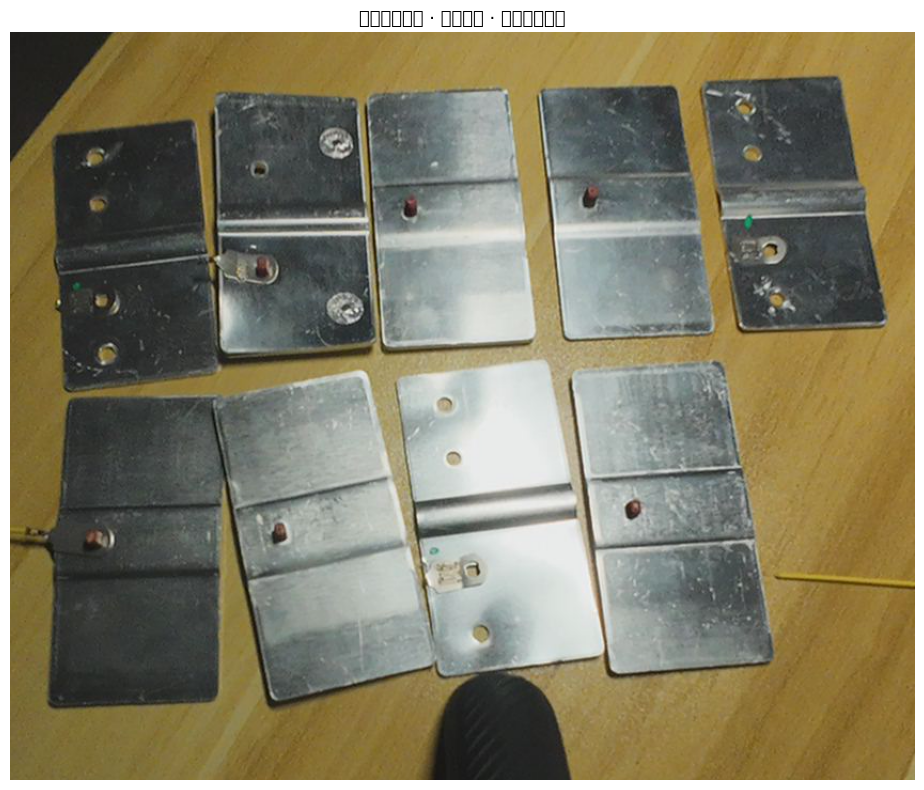

In [2]:
import onsite_utils as onsite
case, image = onsite.load_case()
print("拍摄时间 UTC:", case["captured_at"])
print("原帧尺寸:", case["source_shape_bgr"], "工件裁切尺寸:", image.shape)
print("来源像素摘要:", case["source_frame_sha256"])
print("数据库证据核验:", case["database_evidence"])
lab.show_images([image], ["当前相机实拍 · 工件区域 · 未作亮度修改"], cols=1, figsize=(10, 8))

## 1. 先确认灯光和相机实际能力

原始相机是 1920×1080、30 fps。整张画面画质通过不代表小焊格已足够清晰。
主系统保存“请求参数”和“设备实际回读”两组数据：本次设备没有提供可用的曝光、增益、对焦回读，
也没有接受自动对焦设置，不能把界面上的设置值当成生效值。补光灯开启是操作者配置，不是灯具传感器测量。

先调整灯的位置：固定相机与工件，单灯斜侧照射，移动灯使镍片上出现可读的明暗纹理；
避免亮斑覆盖焊格。需要时试两侧低角度光和柔光，反光仍强时再试交叉偏振并补足亮度。
这里的“环境暗”不等于光学暗场；真正暗场是让镜面反射避开镜头、保留散射纹理。
本课无法从 RGB 图反推光谱，也没有自动控制物理补光灯。

请求的补光/相机参数: {'scene': 'night_fill_light', 'lamp_on': True, 'exposure': None, 'autofocus': True, 'auto_exposure': True}
设备实际回读: {'width': 1920.0, 'height': 1080.0, 'fps': 30.0, 'backend': 'MediaFoundation', 'exposure': None, 'gain': None, 'focus': None, 'white_balance': None, 'controls_supported': False, 'requested_controls_accepted': {'autofocus': False}}
原始全画面质量: {"basis": "native_luma_pixels_sharpness_at_max_640_side", "reasons": [], "contrast": 147.0, "reliable": true, "sharpness": 377.136, "brightness": 94.271, "dark_fraction": 0.121578, "saturated_fraction": 3e-06}
工件裁切质量: {'brightness': 118.565, 'sharpness': 139.774, 'dark_ratio': 0.00026, 'overexposed_ratio': 1e-05, 'width': 847, 'height': 700}


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 28784 (\N{CJK UNIFIED IDEOGRAPH-7070}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 27966 (\N{CJK UNIFIED IDEOGRAPH-6D3E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-begin

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26263 (\N{CJK UNIFIED IDEOGRAPH-6697}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


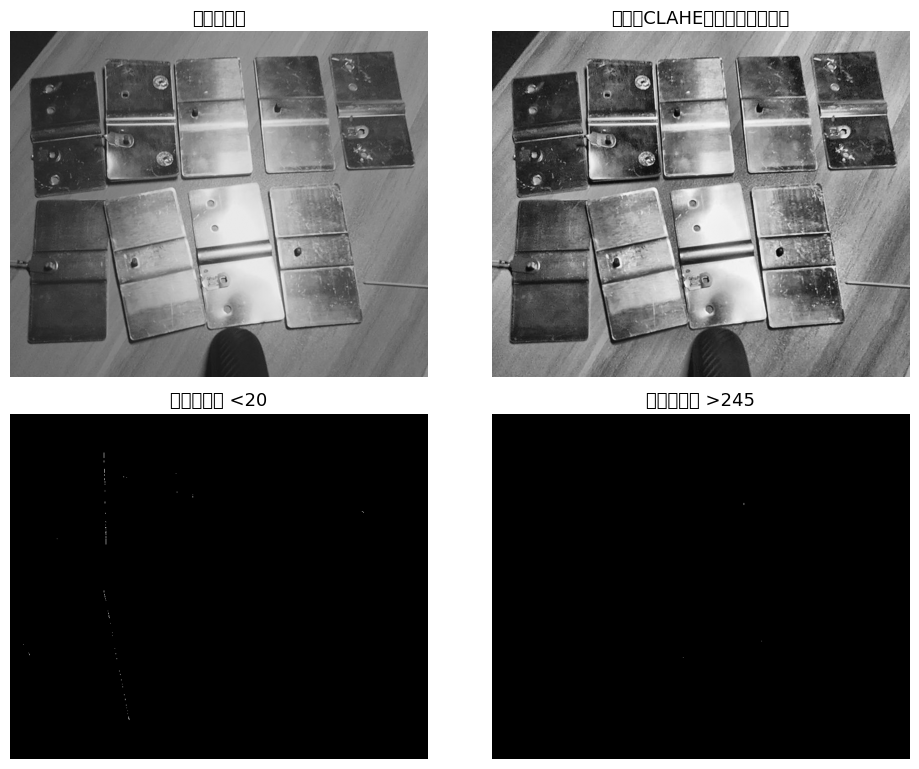

In [3]:
print("请求的补光/相机参数:", case["lighting_requested"])
print("设备实际回读:", case["camera_reported"])
print("原始全画面质量:", json.dumps(case["live_result"]["quality"], ensure_ascii=False))
print("工件裁切质量:", lab.image_quality(image))
g = lab.gray(image)
enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
dark = np.where(g < 20, 255, 0).astype(np.uint8)
glare = np.where(g > 245, 255, 0).astype(np.uint8)
lab.show_images([g, enhanced, dark, glare],
    ["实拍原灰度", "派生：CLAHE，仅增强现有细节", "原图暗像素 <20", "原图亮像素 >245"], cols=2)

## 2. 二值化、边缘和纹理分别看什么

CLAHE 不是补光，也无法恢复已过曝或欠采样的焊格。先保留原图，派生图用于解释算法。
Otsu 找明暗区域，低饱和金属掩膜是另一组候选，形态学修补小孔；都可能把线缆、背景、相邻工件误并。
Canny 体现边缘，局部标准差体现纹理强弱；不能直接把“纹理强”当成焊好。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 39281 (\N{CJK UNIFIED IDEOGRAPH-9971}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21644 (\N{CJK UNIFIED IDEOGRAPH-548C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23646 (\N{CJK UNIFIED IDEOGRAPH-5C5E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 38381 (\N{CJK UNIFIED IDEOGRAPH-95ED}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36816 (\N{CJK UNIFIED IDEOGRAPH-8FD0}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 31639 (\N{CJK UNIFIED IDEOGRAPH-7B97}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23616 (\N{CJK UNIFIED IDEOGRAPH-5C40}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 37096 (\N{CJK UNIFIED IDEOGRAPH-90E8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 39281 (\N{CJK UNIFIED IDEOGRAPH-9971}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21644 (\N{CJK UNIFIED IDEOGRAPH-548C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

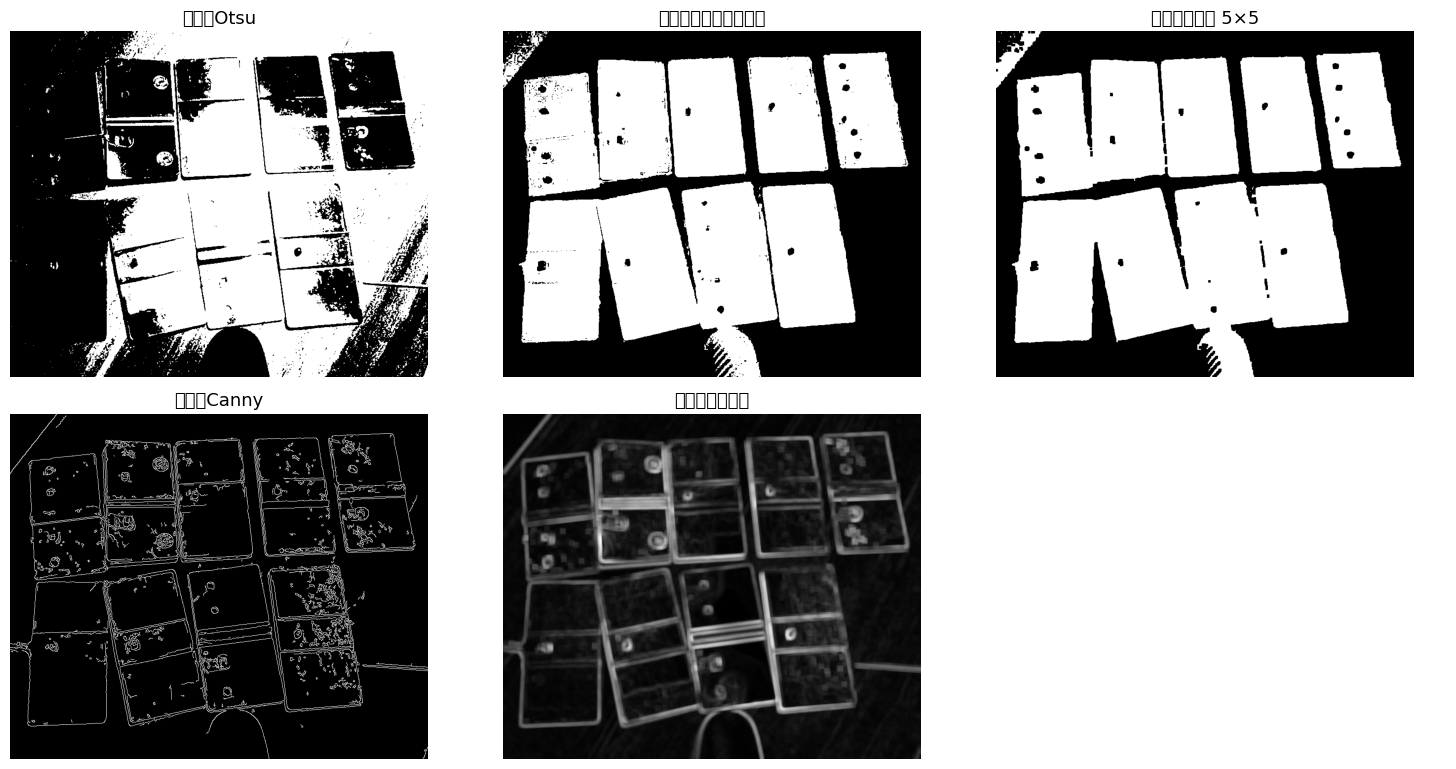

简单连通域候选数: 5 （不等于电芯或汇流排真值）


In [4]:
_, otsu = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
metal = cv2.inRange(hsv, np.array([0, 0, 35], np.uint8), np.array([179, 55, 255], np.uint8))
closed = cv2.morphologyEx(metal, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
edges = cv2.Canny(g, 60, 150)
texture = cv2.normalize(lab.local_std(g), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
lab.show_images([otsu, metal, closed, edges, texture],
    ["派生：Otsu", "派生：低饱和金属候选", "派生：闭运算 5×5", "派生：Canny", "派生：局部纹理"], cols=3)
simple = lab.component_boxes(closed, min_area=400)
print("简单连通域候选数:", len(simple), "（不等于电芯或汇流排真值）")

## 3. 实际定位、切分和编号，不固定九个位置

下方调用主项目 `backend/classical.py`，代码摘要锁定到采样时的版本。
需将有访问权限的 [battery-weld](https://github.com/XuelinHu/battery-weld) 克隆到课程工作区同级目录；当前目录结构下可执行 `git clone git@github.com:XuelinHu/battery-weld.git ../../../battery-weld`。
本课不读取主项目私有参考图片，只运行其传统金属轮廓分组、粘连处理和严格拒判逻辑。
裁切会改变背景和处理尺度，原系统全画面结果与本课裁切重算结果分别展示，禁止互相冒充。

每帧重新检测，候选数量由图像产生。编号是当前视野排序，不是永久身份，也不会每帧把同一工件累计入总数。
这张图是单一固定场景，不能据此宣称适应了所有 N×M 排列。
本次目视复核约为上排五件、下排四件，与候选数相符；但框仍是粗定位，部分带入相邻区域或背景，
下排中央候选还混入前景遮挡物。因此“数出九个”不等于完成精确分割，也不等于焊接识别通过。

采集时全画面系统输出: {'ng': 0, 'ok': 0, 'review': 9, 'busbars': 9, 'nickel_missing': 0, 'nickel_present': 0, 'nickel_unknown': 9}
本课裁切重算输出: {'busbars': 9, 'nickel_present': 0, 'nickel_missing': 0, 'nickel_unknown': 9, 'ok': 0, 'ng': 0, 'review': 9}
数量依据: detected_busbar_candidates_not_cell_count | 未填人工数量真值: None


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 31995 (\N{CJK UNIFIED IDEOGRAPH-7CFB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 32479 (\N{CJK UNIFIED IDEOGRAPH-7EDF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26694 (\N{CJK UNIFIED IDEOGRAPH-6846}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26144 (\N{CJK UNIFIED IDEOGRAPH-6620}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23556 (\N{CJK UNIFIED IDEOGRAPH-5C04}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

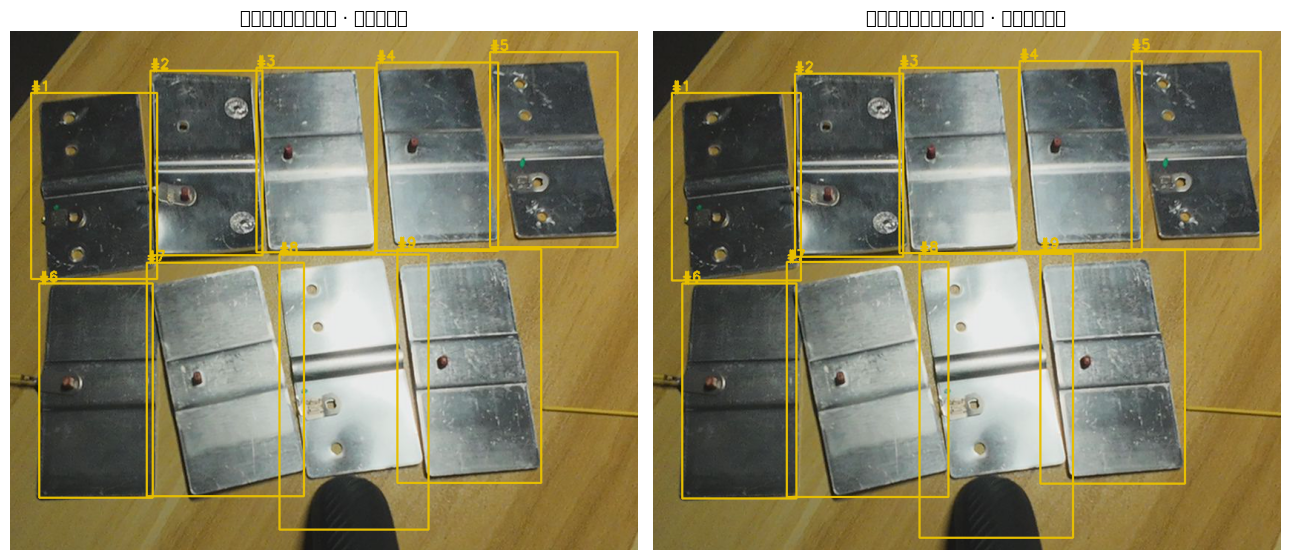

In [5]:
result, replay_config = onsite.replay(image, case)
boxes = onsite.pixel_boxes(result["targets"], image)
captured = lab.draw_boxes(image, onsite.captured_boxes(case))
replayed = lab.draw_boxes(image, boxes)
print("采集时全画面系统输出:", case["live_result"]["counts"])
print("本课裁切重算输出:", result["counts"])
print("数量依据:", result["observed_basis"], "| 未填人工数量真值:", case["ground_truth"]["busbar_count"])
lab.show_images([captured, replayed],
    ["原系统框映射到裁切 · 黄色待复核", "同一传统引擎无模板重跑 · 当前视野编号"], cols=2, figsize=(13, 6))

## 4. 逐个汇流排看镍片和七格

大框内继续找小框是正确的层级检测。本次系统没有可靠定位镍片，也没有七格窗口，
所以不能在照片上编造七个精确小框。下面裁切的是**自动汇流排候选**；表格忠实展示未知状态。
大框和镍片小框应分别标注，七格还需位置与 GOOD/BAD/UNKNOWN 真值。
本次 #6、#7 候选框贴近边缘，#8 带入前景与邻近背景；这些定位问题应在后续标注、分割和复核中处理，
不能把九张候选裁切视作九个已精确分出的镍片。

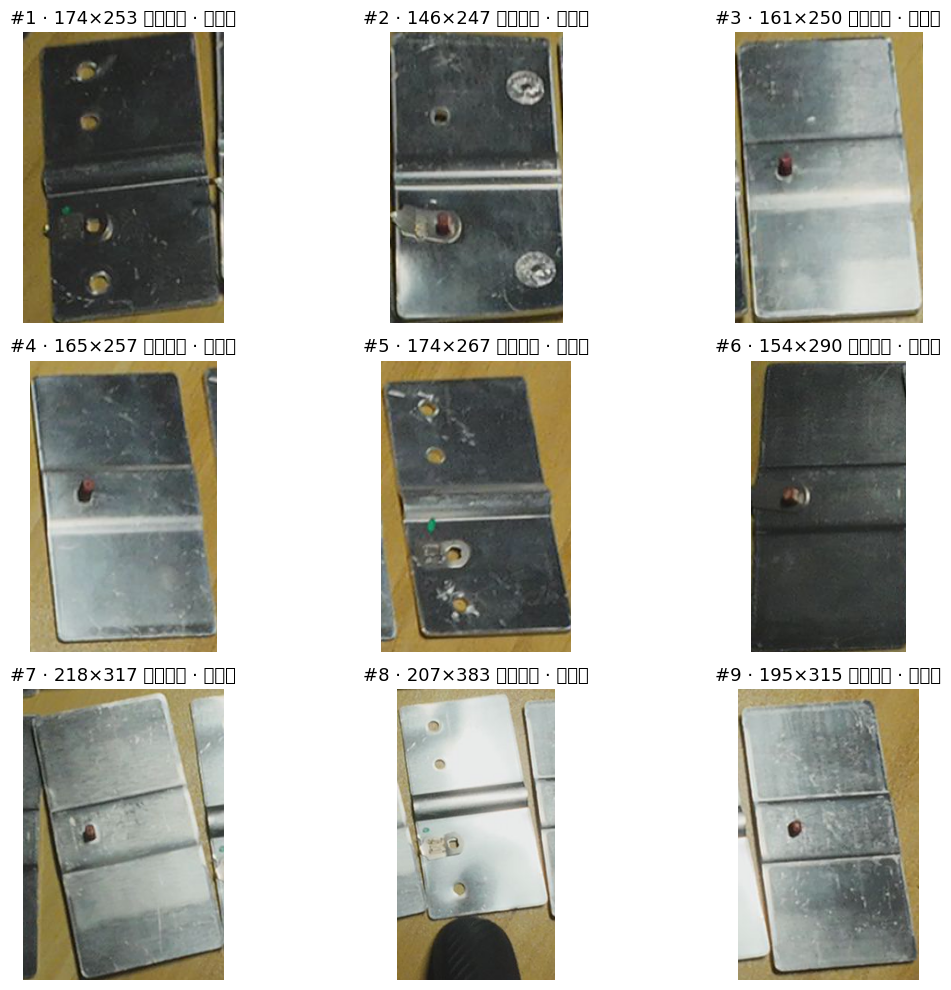

[
  {
    "编号": 1,
    "镍片": "UNKNOWN",
    "七格": [
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN"
    ],
    "已知好格": 0,
    "判定": "REVIEW",
    "原因": [
      "BUSBAR_GEOMETRY_UNCONFIRMED",
      "BUSBAR_OUTLINE_INCOMPLETE",
      "SEVEN_SLOT_CALIBRATION_NOT_VERIFIED",
      "WELD_WINDOW_UNLOCATED"
    ]
  },
  {
    "编号": 2,
    "镍片": "UNKNOWN",
    "七格": [
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN"
    ],
    "已知好格": 0,
    "判定": "REVIEW",
    "原因": [
      "INSUFFICIENT_PIXELS_FOR_LOCAL_SEARCH",
      "SEVEN_SLOT_CALIBRATION_NOT_VERIFIED",
      "WELD_WINDOW_UNLOCATED"
    ]
  },
  {
    "编号": 3,
    "镍片": "UNKNOWN",
    "七格": [
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN",
      "UNKNOWN"
    ],
    "已知好格": 0,
    "判定": "REVIEW",
    "原因": [
      "INSUFFICIENT_PIXELS_FOR_LOCAL_SEARC

In [6]:
crops, titles = [], []
rows = []
for target, box in zip(result["targets"], boxes):
    x, y, w, h = box["bbox"]
    crop = image[max(0,y):min(image.shape[0],y+h), max(0,x):min(image.shape[1],x+w)]
    if crop.size:
        crops.append(crop)
        titles.append(f"#{target['index']} · {w}×{h} 原生像素 · 待复核")
    slots = target["weld"]["slots7"]
    rows.append({"编号": target["index"], "镍片": target["nickel"]["status"],
        "七格": [s["status"] for s in slots], "已知好格": target["weld"]["good_count"],
        "判定": target["status"], "原因": target["reason"]})
lab.show_images(crops, titles, cols=3, figsize=(12, 10))
print(json.dumps(rows, ensure_ascii=False, indent=2))

## 5. 像素预算：放大图片不能增加焊格细节

如未定位焊格，就不能报告真实“每格像素”。下面只演示选中工件的原生裁切和最近邻放大；
看见大像素块说明显示变大了，并没有拍到更多细节。下一步应缩小单相机视野、改善对焦/补光，
或增加相机/移动拍摄，使真实七格可分辨，然后重新采样校准。当前单帧还不足以比较九相机与移动方案的产线可靠性。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21160 (\N{CJK UNIFIED IDEOGRAPH-52A8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36817 (\N{CJK UNIFIED IDEOGRAPH-8FD1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 37051 (\N{CJK UNIFIED IDEOGRAPH-90BB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

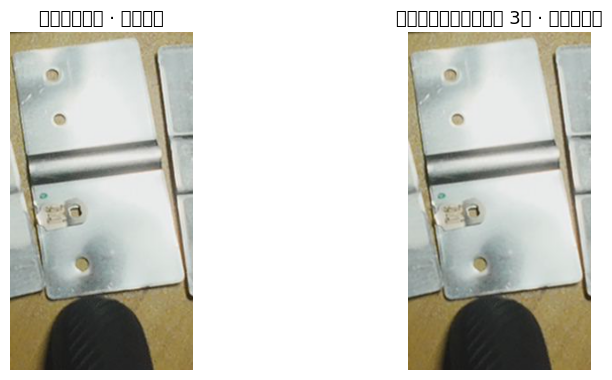

可靠定位的镍片框数: 0
可靠定位的焊格框数: 0


In [7]:
largest = max(crops, key=lambda c: c.shape[0] * c.shape[1])
zoom = cv2.resize(largest, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
lab.show_images([largest, zoom], ["自动工件裁切 · 原生像素", "派生：最近邻显示放大 3倍 · 没有新细节"], cols=2)
print("可靠定位的镍片框数:", sum(t["nickel"]["bbox"] is not None for t in result["targets"]))
print("可靠定位的焊格框数:", sum(s["bbox"] is not None for t in result["targets"] for s in t["weld"]["slots7"]))

## 6. 七格至少五格：单独验证规则，不能伪装成实拍识别

以下输入明确是**合成规则测试**：镍片确认存在、全部七格清楚时，五格好为绿色、四格好为红色；
只要存在未确认格、画质不足或镍片未知，保守地显示黄色待复核。
实拍中的未知不能用这些演示值替换。

In [8]:
synthetic = {
    "合成：清晰5格": lab.seven_slot_verdict(["OK"]*5 + ["NG"]*2),
    "合成：清晰4格": lab.seven_slot_verdict(["OK"]*4 + ["NG"]*3),
    "合成：有未知": lab.seven_slot_verdict(["OK"]*5 + [None]*2),
    "合成：缺镍片": lab.seven_slot_verdict(["NG"]*7, nickel_present=False),
}
assert [v["status"] for v in synthetic.values()] == ["OK", "NG", "REVIEW", "NG"]
print(json.dumps(synthetic, ensure_ascii=False, indent=2))
print("当前真实画面判定仍为:", result["status"])

{
  "合成：清晰5格": {
    "good_count": 5,
    "required_good": 5,
    "total_slots": 7,
    "slots": [
      "OK",
      "OK",
      "OK",
      "OK",
      "OK",
      "NG",
      "NG"
    ],
    "status": "OK",
    "reason": "七格外观中5格符合已确认标准"
  },
  "合成：清晰4格": {
    "good_count": 4,
    "required_good": 5,
    "total_slots": 7,
    "slots": [
      "OK",
      "OK",
      "OK",
      "OK",
      "NG",
      "NG",
      "NG"
    ],
    "status": "NG",
    "reason": "七格外观中4格符合已确认标准"
  },
  "合成：有未知": {
    "good_count": 5,
    "required_good": 5,
    "total_slots": 7,
    "slots": [
      "OK",
      "OK",
      "OK",
      "OK",
      "OK",
      null,
      null
    ],
    "status": "REVIEW",
    "reason": "七格未全部清晰判读，未知不能自动填为合格"
  },
  "合成：缺镍片": {
    "good_count": 0,
    "required_good": 5,
    "total_slots": 7,
    "slots": [
      "NG",
      "NG",
      "NG",
      "NG",
      "NG",
      "NG",
      "NG"
    ],
    "status": "NG",
    "reason": "已确认缺少镍片"
  }
}
当前真实画面判定仍为: REVIEW


## 7. 实拍证据入库与教学数据库

这次采样使用原系统“保存当前帧”，确认该事件已进入检测数据库，再校验：
PNG 文件 SHA256 与保存记录一致、解码后 BGR8 像素 SHA256 与实际检测帧一致。
原始全画面保留在检测系统和本地忽略目录；网页只包含经授权的工件裁切和白名单元数据。

下方另外写入教学 SQLite：把源帧摘要、裁切摘要、灯光请求、设备回读、质量与重算参数一同保存，
重跑同一事件不重复插入。这里的 outbox 保持 pending，**没有发送 MES，也不伪造 MES 回执**。
实际检测数据库已确认保存，与本课演示数据库的 pending 是两件独立的事。

In [9]:
db = lab.create_database(INDUSTRIAL_ROOT / "runtime/onsite_teaching.sqlite3")
recipe = {"required_good": 5, "total_slots": 7, "captured_at_utc": case["captured_at"],
    "crop_sha256": case["image_sha256"], "crop_xywh": case["crop_xywh"],
    "capture_engine_source_sha256": case["engine_source_sha256"],
    "engine_source_sha256": case.get("replay_engine_source_sha256", case["engine_source_sha256"]), "replay_config": replay_config,
    "lighting_requested": case["lighting_requested"], "camera_reported": case["camera_reported"]}
arguments = dict(event_key=case["case_id"]+":replay:"+recipe["engine_source_sha256"][:12], source_id=case["case_id"],
    source_sha256=case["source_frame_sha256"], evidence_path=case["image"],
    result=result, recipe=recipe, quality=result["quality"], observed=result["observed"])
record_id, created = lab.save_inspection(db, **arguments)
duplicate_id, duplicate_created = lab.save_inspection(db, **arguments)
assert duplicate_id == record_id and not duplicate_created
state = db.execute("SELECT state FROM sync_outbox WHERE inspection_id=?", (record_id,)).fetchone()[0]
db.close()
print("真实检测系统入库:", case["database_evidence"])
print("教学SQLite记录:", record_id, "| 重复事件新增:", duplicate_created, "| 教学outbox:", state)
print("当前候选:", result["observed"], "| 合格:", result["counts"]["ok"],
      "| 不合格:", result["counts"]["ng"], "| 待复核:", result["counts"]["review"])

真实检测系统入库: {'acknowledged': True, 'png_file_hash_verified': True, 'decoded_bgr_hash_verified': True}
教学SQLite记录: 4 | 重复事件新增: False | 教学outbox: pending
当前候选: 9 | 合格: 0 | 不合格: 0 | 待复核: 9


## 8. 摆歪、透视和工件弯曲是三种情况

平面内摆歪：旋转矩形确定方向，再将当前可见区域转正。平面透视：有可靠对应点时用 RANSAC 单应矩阵映射，
再把镍片和七格窗口映回原图。弯曲、翘起等三维变形不能用一个平面变换还原，需补充视角或高度测量。
本系统的轮廓分支提供旋转矩形，不把它声称为真实物体四角的精确透视标定。

下面是同一实拍重跑得到的方向轮廓与方向校正图。未见几何告警不等于排除了遮挡；
方向校正、插值放大和黑色边界填充均不会产生新的真实焊格。

采样时引擎摘要: 239c756bdbbc444a9368d85506b418cb567cba5c875fb8a88de54b6b6258e774
本次重算引擎摘要: edfab0c46f813be3e59e4fbfcb7339b3f9747767ae68980a02827e7b2772764e
当前几何摘要: {"partial_candidates": 0, "occlusion_suspected": 2, "blocked_candidates": 2, "rotated_candidates": 4, "hidden_object_count": null, "total_physical_count_verified": false, "policy": "unclear_or_incomplete_is_review_no_hidden_pixel_completion", "unresolved_region_count": 0, "unresolved_regions": [], "unresolved_basis": "unassigned_low_chroma_pixels_may_include_background", "scene_action": "仅统计可见候选，完全隐藏的数量未知"}


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 38469 (\N{CJK UNIFIED IDEOGRAPH-9645}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26059 (\N{CJK UNIFIED IDEOGRAPH-65CB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36716 (\N{CJK UNIFIED IDEOGRAPH-8F6C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36718 (\N{CJK UNIFIED IDEOGRAPH-8F6E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 24275 (\N{CJK UNIFIED IDEOGRAPH-5ED3}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

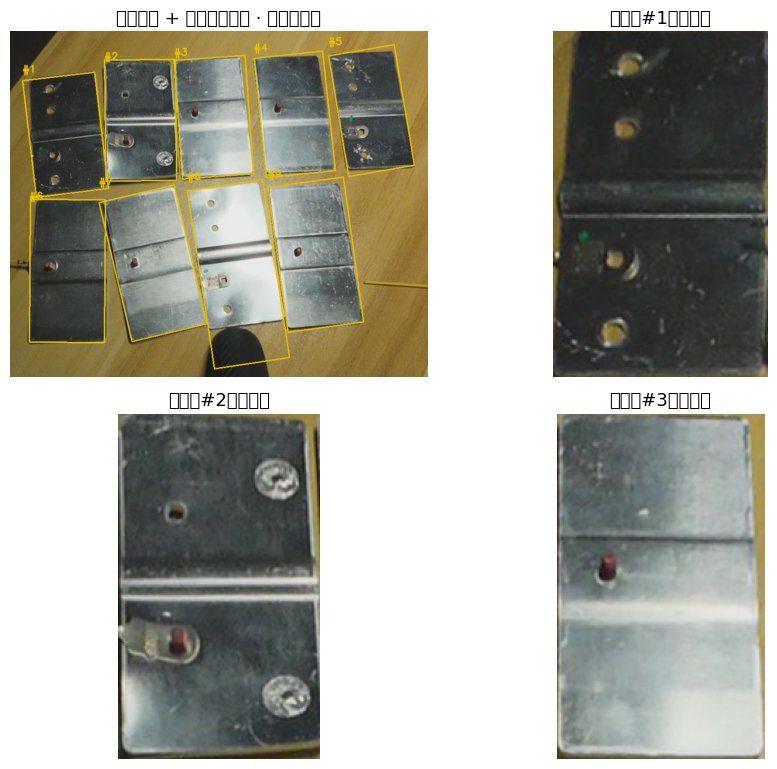

In [10]:
print("采样时引擎摘要:", case["engine_source_sha256"])
print("本次重算引擎摘要:", case.get("replay_engine_source_sha256", case["engine_source_sha256"]))
print("当前几何摘要:", json.dumps(result["geometry"], ensure_ascii=False))
aligned = [onsite.align_target(image, target) for target in result["targets"][:3]]
lab.show_images([onsite.draw_pose(image, result), *aligned],
    ["原始实拍 + 实际旋转轮廓 · 黄框待复核", *[f"派生：#{t['index']}方向校正" for t in result["targets"][:3]]], cols=2)

## 9. 遮挡、出画：保留候选，暂停质量判定

系统新增几何门控：贴边/出画、轮廓填充不足、碎裂、候选多边形重叠，均给出具体原因和补拍动作。
框外仍有较大的金属候选区域时，另报未分离区域警告：当前数量不完整。它可能包括背景，不能直接累加为工件数。
这些是**疑似遮挡的几何线索**，阴影、孔洞和背景也可能触发；不是逐像素遮挡真值。
平滑遮挡恰好覆盖成规则形状时，传统轮廓可能看不出来，仍需镍片/焊格局部证据门控。

以下全部由同一张已授权实拍派生：旋转、黑块遮挡、裁边、完全遮住视野，**不是新采集的独立验证照片**。
输出为实际算法运行结果；计数可能减少或产生误候选，未检测到不代表不存在。
不按矩阵补出隐藏工件、不修补隐藏焊格、不用上一帧的绿色替代本帧未知。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 25193 (\N{CJK UNIFIED IDEOGRAPH-6269}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30011 (\N{CJK UNIFIED IDEOGRAPH-753B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 38450 (\N{CJK UNIFIED IDEOGRAPH-9632}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGRAPH-8FB9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

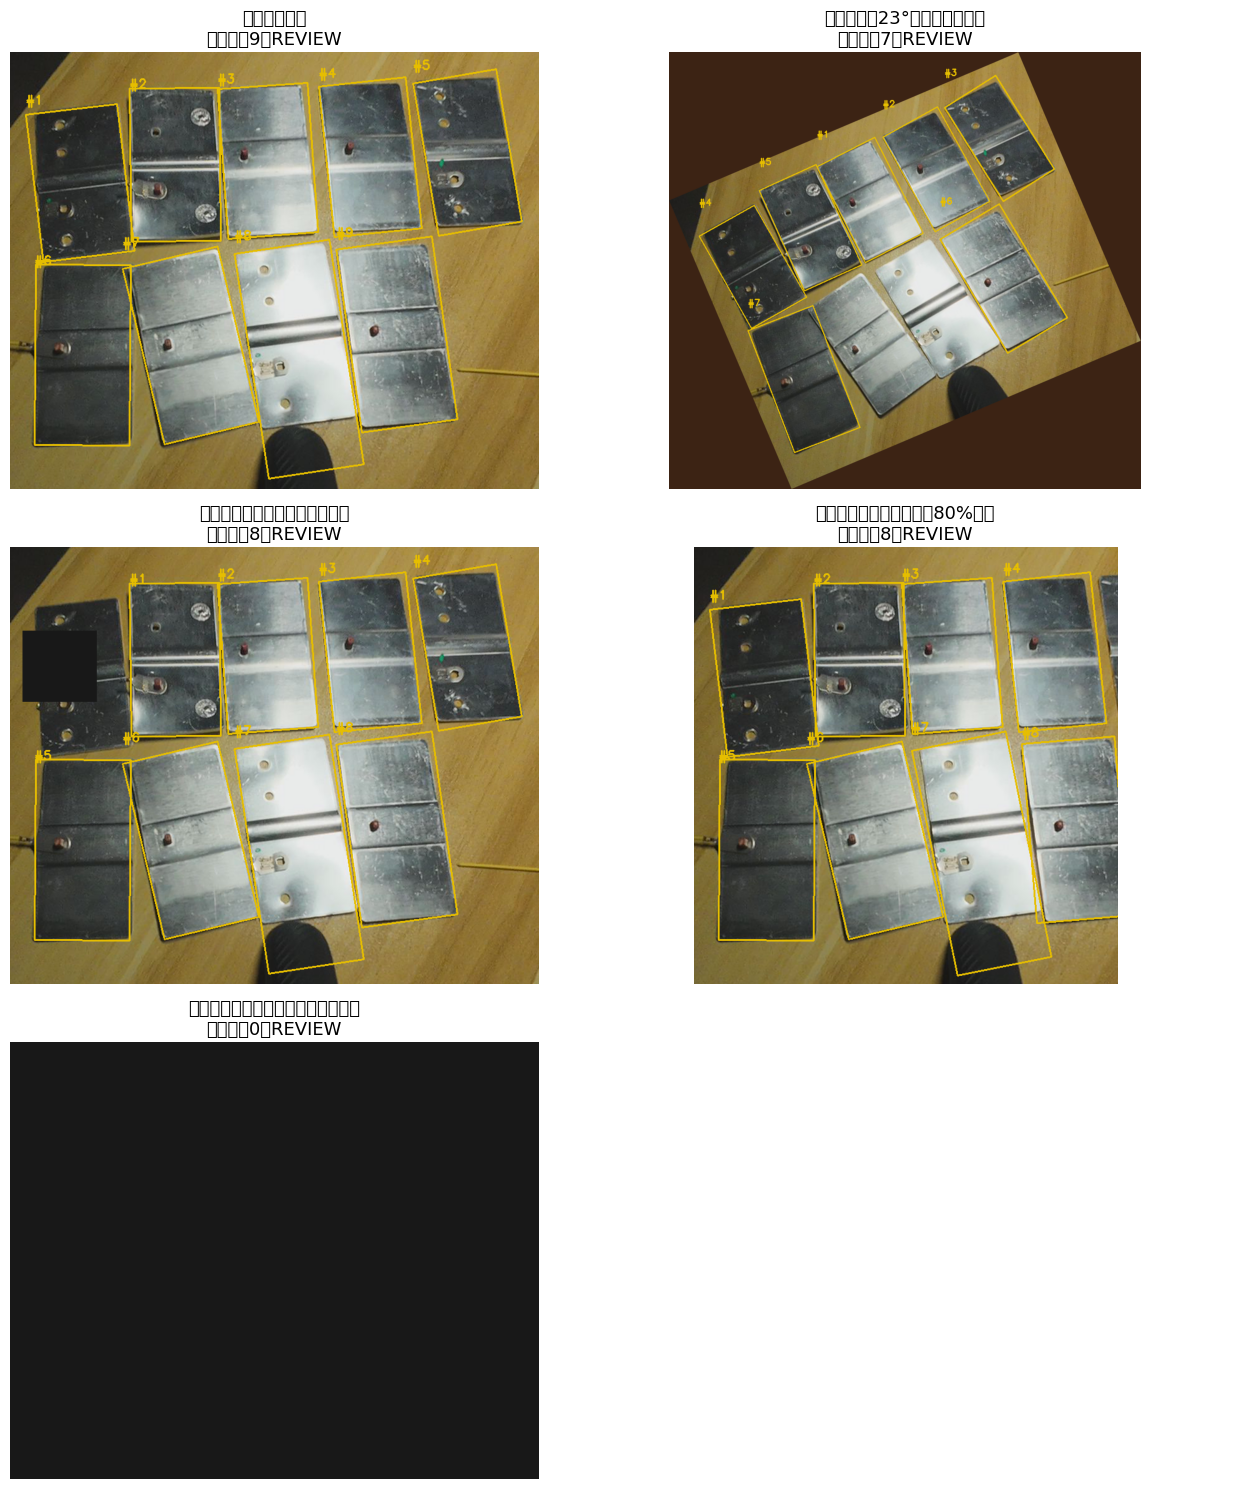

[
  {
    "case": "原始实拍裁切",
    "derived_from_sha256": "0f0ae046b4dc2239348fbefb692b3e2326488ed5bf4fbabb14d14d778cd40707",
    "observed": 9,
    "status": "REVIEW",
    "geometry": {
      "partial_candidates": 0,
      "occlusion_suspected": 2,
      "blocked_candidates": 2,
      "rotated_candidates": 4,
      "hidden_object_count": null,
      "total_physical_count_verified": false,
      "policy": "unclear_or_incomplete_is_review_no_hidden_pixel_completion",
      "unresolved_region_count": 0,
      "unresolved_regions": [],
      "unresolved_basis": "unassigned_low_chroma_pixels_may_include_background",
      "scene_action": "仅统计可见候选，完全隐藏的数量未知"
    },
    "counts": {
      "busbars": 9,
      "nickel_present": 0,
      "nickel_missing": 0,
      "nickel_unknown": 9,
      "ok": 0,
      "ng": 0,
      "review": 9
    }
  },
  {
    "case": "派生：旋转23°，扩画布防裁边",
    "derived_from_sha256": "0f0ae046b4dc2239348fbefb692b3e2326488ed5bf4fbabb14d14d778cd40707",
    "observed": 7,
    "stat

4826

In [11]:
challenges = onsite.derived_challenges(image, result)
challenge_outputs, titles, challenge_rows = [], [], []
for name, challenge in challenges:
    measured_result, _ = onsite.replay(challenge, case)
    challenge_outputs.append(onsite.draw_pose(challenge, measured_result))
    titles.append(name + f"\n实际候选{measured_result['observed']}，{measured_result['status']}")
    challenge_rows.append({"case": name, "derived_from_sha256": case["image_sha256"],
        "observed": measured_result["observed"], "status": measured_result["status"],
        "geometry": measured_result["geometry"], "counts": measured_result["counts"]})
lab.show_images(challenge_outputs, titles, cols=2, figsize=(13, 15))
print(json.dumps(challenge_rows, ensure_ascii=False, indent=2))
assert challenge_rows[-1]["observed"] == 0 and challenge_rows[-1]["status"] == "REVIEW"
assert all(row["geometry"]["hidden_object_count"] is None for row in challenge_rows)
(INDUSTRIAL_ROOT / "outputs/public/onsite_robustness.json").write_text(
    json.dumps({"independent_validation": False, "cases": challenge_rows}, ensure_ascii=False, indent=2), encoding="utf-8")

## 10. 现场处理顺序与系统使用

1. 摆歪但完整：点击实时画面中的编号，查看同帧方向校正图，再看镍片及七格像素是否足够。
2. 两件贴在一起或被挡：拉开工件间距、移开线缆等遮挡，再拍新帧；不要把可见碎片当成多个电芯。
3. 贴边或出画：把整个目标移入视野，保留边距；若大视野影响焊格分辨率，改为多视野拍摄。
4. 静态相机和静态遮挡：多等几帧不会看到被挡部位。补光能改善明暗，无法穿透遮挡，需换视角或移动遮挡物。
5. 七格中任何格未知：保持黄色；七格均可判读且其他前提通过后，至少五格合格为绿、明确不足为红。

实时界面显示方向、旋转轮廓、疑似遮挡/出画原因和补拍建议；历史记录保留这些字段。
当前堆叠现场曾出现旧、新引擎在同一预览帧都仅定位1件，系统会提示未分离区域和数量不完整，
不能把“一个候选”解释为“只有一个工件”。该当前私有调试预览没有加入本教程图片。
每秒质量记录保存几何摘要，保存当前帧时保存逐件完整结果；不会把每个视频帧都写入数据库。
算法只报可见候选，完全隐藏的工件数量未知。标注应另外记录 visible/occluded/truncated，
并将独立物理工件和采集会话分开划分训练/验收集，不能把同一张图的旋转派生当新测试样本。

原理依据：[OpenCV 轮廓与旋转矩形](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)、
[OpenCV 特征匹配与单应变换](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html)、
[MVTec 匹配与遮挡说明](https://www.mvtec.com/doc/merlic/26.10/manual/en-us/Content/Tool_reference/Processing/Checking/check_presence_with_matching.html)。
MVTec 仅作工业实践资料参考，本项目未引入 HALCON/MERLIC 依赖或复制其性能结论。

## 如何换成下一次现场数据

实时检测依然由笔记本的原系统采集，服务器不直接连接这台 USB 相机。
用户确认新样本可用于教材后，再显式导出、目视检查、核验摘要和执行课程；
采样脚本默认拒绝覆盖已有策展清单。不要把密码、完整数据库记录或无关照片复制进网页。

本课实拍按用户 2026-11-18 的明确要求加入教学，照片权利仍归原权利人；
仅授权本项目教程展示，没有将其声明为 CC0 或通用开源数据。前十课公开素材各保留原许可。
详细范围见 [素材与许可](../DATA_SOURCES.md)。